# TTD Power Analysis — per-segment MDE vs. time (pre-period only)

Split out of `TTD3_Pricing_T2_Rollout.ipynb` since this doesn't depend on any specific
experiment (T2, rollout, etc.) — it's a property of the general sharethis population's
own pre-period revenue noise, split by (geo, bucket) cell, and applies equally to any
experiment drawn from that population.

Computes the **per-segment minimum detectable effect (MDE%)** as a function of `weeks`
of observation, using only pre-period week-to-week noise (`sd_pre`) — no post-period
sample size or segment count assumed anywhere in the formula.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm

pd.set_option('display.width', 160)

In [2]:
# ─── Config ───────────────────────────────────────────────────────────────
data_path = "/Users/ravirajan/code/data/TTD"

ttd_file = f"{data_path}/TTD-20260101-0914-AllOnly.csv"  # full history through 9/14
rev_pool_file = f"{data_path}/RankedByRevenueJuly.csv"   # for bucketing (monthly revenue, July)

PROVIDER = 'sharethis'
BUCKET_BOUNDARIES = [1000, 100, 10, 1]  # monthly revenue thresholds, same as TTD3_Pricing

# 6 clean pre-period weeks before the 8/17 T2/rollout launch -- nothing changed a
# segment's live price in this window (confirmed in TTD3_Pricing_T2_Rollout.ipynb's
# own 5/26->8/17 reconciliation check), so it's a safe, stable pre-period noise sample.
test_df_start = "2026-07-01"
last_pre_week = "2026-08-16"

In [3]:
dat0 = pd.read_csv(ttd_file, low_memory=False).replace(' ', None)
dat0 = dat0[dat0['Third_Party_Data_Provider_Id'] == PROVIDER].copy()
rev_pool = pd.read_csv(rev_pool_file)
rev_pool = rev_pool[rev_pool['Third_Party_Data_Provider_Id'] == PROVIDER].copy()
rev_pool['revenue'] = rev_pool['revenue'].fillna(0)

print(f"After restricting to {PROVIDER}:")
print("dat0:", dat0.shape, "| weeks:", sorted(dat0['Week_Start_Date'].unique()))

After restricting to sharethis:
dat0: (133008, 21) | weeks: ['2026-01-05 00:00:00+00', '2026-01-12 00:00:00+00', '2026-01-19 00:00:00+00', '2026-01-26 00:00:00+00', '2026-02-02 00:00:00+00', '2026-02-09 00:00:00+00', '2026-02-16 00:00:00+00', '2026-02-23 00:00:00+00', '2026-03-02 00:00:00+00', '2026-03-09 00:00:00+00', '2026-03-16 00:00:00+00', '2026-03-23 00:00:00+00', '2026-03-30 00:00:00+00', '2026-04-06 00:00:00+00', '2026-04-13 00:00:00+00', '2026-04-20 00:00:00+00', '2026-04-27 00:00:00+00', '2026-05-04 00:00:00+00', '2026-05-11 00:00:00+00', '2026-05-18 00:00:00+00', '2026-05-25 00:00:00+00', '2026-06-01 00:00:00+00', '2026-06-08 00:00:00+00', '2026-06-15 00:00:00+00', '2026-06-22 00:00:00+00', '2026-06-29 00:00:00+00', '2026-07-06 00:00:00+00', '2026-07-13 00:00:00+00', '2026-07-20 00:00:00+00', '2026-07-27 00:00:00+00', '2026-08-03 00:00:00+00', '2026-08-10 00:00:00+00', '2026-08-17 00:00:00+00', '2026-08-24 00:00:00+00', '2026-08-31 00:00:00+00', '2026-09-07 00:00:00+00', '20

In [4]:
def get_geo(litems):
    check = ['Asia', 'US', 'Global', 'APAC']
    for c in check:
        if c in litems:
            return c
    return 'Unknown'

dat = dat0.copy()
dat['geo'] = dat['Full_Path'].apply(lambda x: get_geo(x.replace(" ", "").split(">")))

# 11 sharethis Full_Paths carry TWO distinct rows per week in the raw file (a hex
# Element_Id and a zero-padded numeric one for the same segment) -- sum before
# building any panel, or these 11 silently fan out 2x per week. See
# TTD3_Pricing_T2_Rollout.ipynb's own note on this for the full investigation.
dat = dat.groupby(
    ['Full_Path', 'Third_Party_Data_Provider_Id', 'Week_Start_Date', 'geo'], as_index=False
)[['Data_Cost', 'Effective_Impression_Count']].sum()

In [5]:
# Bucket on the full Ranked_by_Revenue universe, same scheme as TTD3_Pricing
_boundaries = sorted(set(BUCKET_BOUNDARIES), reverse=True)

def _fmt(x):
    return f"{x:g}+"

_labels = [_fmt(b) for b in _boundaries]
ZERO_BUCKET_LABEL = '0+'
BUCKET_ORDER = [ZERO_BUCKET_LABEL] + list(reversed(_labels))

_rev_pool_revenue = rev_pool['revenue'].fillna(0.0)
rev_pool['bucket'] = np.select(
    [_rev_pool_revenue >= b for b in _boundaries], _labels, default=ZERO_BUCKET_LABEL
)
bucket_by_seg = rev_pool.drop_duplicates(['Full_Path', 'Third_Party_Data_Provider_Id']) \
    .set_index(['Full_Path', 'Third_Party_Data_Provider_Id'])['bucket']

def assign_bucket(df):
    """Raw, per-segment revenue bucket -- adds bucket/geo columns."""
    df = df.copy()
    df['bucket'] = df.set_index(['Full_Path', 'Third_Party_Data_Provider_Id']).index.map(bucket_by_seg)
    df['bucket'] = df['bucket'].fillna(ZERO_BUCKET_LABEL)
    df['geo'] = df['Full_Path'].apply(lambda x: get_geo(x.replace(" ", "").split(">")))
    return df

print("BUCKET_ORDER:", BUCKET_ORDER)

BUCKET_ORDER: ['0+', '1+', '10+', '100+', '1000+']


## Population-wide pre-period noise, per (geo, bucket) cell

Uses EVERY sharethis segment's own pre-period week-to-week variability (not any one
experiment's small sample), since nothing was treated before 8/17 for anyone.

In [6]:
_pre_mask = (dat['Week_Start_Date'] > test_df_start) & (dat['Week_Start_Date'] <= last_pre_week)
_wk = dat[_pre_mask].pivot_table(index='Full_Path', columns='Week_Start_Date', values='Data_Cost', fill_value=0.0)
N_PRE = _wk.shape[1]

_pop = pd.DataFrame({'sd_pre': _wk.std(axis=1, ddof=1), 'baseline': _wk.mean(axis=1)}).reset_index()
_pop['Third_Party_Data_Provider_Id'] = PROVIDER
_pop = assign_bucket(_pop).set_index('Full_Path')  # adds bucket, geo columns

cell_noise = _pop.groupby(['geo', 'bucket']).agg(
    n_pop=('sd_pre', 'size'), sd_pre=('sd_pre', 'median'), baseline=('baseline', 'median')
)
print(f"Pre-period noise, per (geo, bucket) cell -- population-wide, n={len(_pop)} sharethis segments, {N_PRE} pre-weeks:")
print(cell_noise.to_string())

Pre-period noise, per (geo, bucket) cell -- population-wide, n=3589 sharethis segments, 6 pre-weeks:
                n_pop      sd_pre    baseline
geo     bucket                               
APAC    0+          1    0.084794    0.175000
        1+          1    0.225514    1.478333
        10+         5    1.741915   19.076667
        100+        5    8.140694   42.226667
Asia    0+       1042    0.000000    0.001667
        1+        139    0.370913    0.526667
        10+        35    2.997542    5.333333
        100+        2   54.023819   56.493333
Global  0+        476    0.004082    0.003333
        1+        228    0.445549    0.769167
        10+       228    2.696057    6.830833
        100+       78   19.488368   47.795833
        1000+      10  132.967212  399.176667
US      0+        496    0.005164    0.005000
        1+        153    0.332711    0.683333
        10+       116    2.239496    8.332500
        100+       58   13.149236   56.420833
        1000+       8  11

## Per-segment MDE% vs. time

Detectability is a property of a segment's own revenue behavior (its (geo, bucket)
cell), not of which experiment it happens to be sitting in -- two segments in the same
cell are equally noisy whether one is in T2 and the other is in a rollout. So there is
no per-experiment table here: the population-wide noise below is the single shared
dataset every experiment's segments draw from.

`MDE% = z_crit * (sd_pre / sqrt(weeks)) / baseline * 100` -- per-segment (no
`/sqrt(n)`), purely a function of `weeks` of observation.

In [7]:
def mde_pct_per_segment(sd_pre, baseline, weeks, alpha=0.05, power=0.80):
    """Per-segment MDE% (no aggregation across segments -- a single segment's own
    detectable effect size), as a function of `weeks` of observation. sd_pre is the
    per-week noise (pre-period, population-wide by (geo,bucket) cell), treated as a
    known, stable value -- purely pre-experimental information, no post-period sample
    size or segment count assumed anywhere in this formula."""
    z_crit = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    se = sd_pre / np.sqrt(weeks)
    return z_crit * se / baseline * 100

## Weeks needed to detect a 50% / 60% MDE

Inverting the formula above: given a target effect size, how many weeks of
observation does a *typical* segment in each bucket need? Pooled (n_pop-weighted)
across geos per bucket, and an overall figure excluding the 0+ bucket (whose
near-zero baseline makes any percentage-based target undefined -- see the rollout
notebook's percentage-impact section for the full argument).

In [8]:
def weeks_for_mde(sd_pre, baseline, mde_pct, n_pre=N_PRE, alpha=0.05, power=0.80):
    """Inverse of mde_pct_per_segment: weeks of observation needed for a single
    segment to detect `mde_pct`, given its own pre-period noise/baseline."""
    z_crit = norm.ppf(1 - alpha / 2) + norm.ppf(power)
    if baseline <= 0:
        return np.nan
    return (z_crit * sd_pre / (mde_pct / 100 * baseline)) ** 2

_ex0 = cell_noise.drop(index=ZERO_BUCKET_LABEL, level='bucket', errors='ignore')

rows = []
for bucket in BUCKET_ORDER:
    if bucket == ZERO_BUCKET_LABEL:
        continue
    sub = cell_noise.xs(bucket, level='bucket', drop_level=False) if bucket in cell_noise.index.get_level_values('bucket') else None
    if sub is None or len(sub) == 0:
        continue
    w = sub['n_pop']
    sd_p = (sub['sd_pre'] * w).sum() / w.sum()
    base_p = (sub['baseline'] * w).sum() / w.sum()
    rows.append({
        'bucket': bucket, 'n_pop': int(w.sum()), 'sd_pre_pooled': round(sd_p, 3), 'baseline_pooled': round(base_p, 3),
        'weeks_@50pct': round(weeks_for_mde(sd_p, base_p, 50), 1),
        'weeks_@60pct': round(weeks_for_mde(sd_p, base_p, 60), 1),
    })

w_all = _ex0['n_pop']
sd_all = (_ex0['sd_pre'] * w_all).sum() / w_all.sum()
base_all = (_ex0['baseline'] * w_all).sum() / w_all.sum()
rows.append({
    'bucket': 'Overall (ex 0+)', 'n_pop': int(w_all.sum()), 'sd_pre_pooled': round(sd_all, 3), 'baseline_pooled': round(base_all, 3),
    'weeks_@50pct': round(weeks_for_mde(sd_all, base_all, 50), 1),
    'weeks_@60pct': round(weeks_for_mde(sd_all, base_all, 60), 1),
})

print(pd.DataFrame(rows).to_string(index=False))

         bucket  n_pop  sd_pre_pooled  baseline_pooled  weeks_@50pct  weeks_@60pct
             1+    605          0.389            0.749           8.5           5.9
            10+    450          2.635            7.172           4.2           2.9
           100+    160         17.312           51.460           3.6           2.5
          1000+     22        161.651          425.204           4.5           3.2
Overall (ex 0+)   1237          6.263           17.194           4.2           2.9


## Why "more segments" and "more weeks" are different levers

Everything above answers one specific question: *how long do you need to watch a
SINGLE segment* to detect a given effect in it. That's deliberately independent of
which experiment the segment is in, or how many other segments are running alongside
it -- per-segment detectability is a property of the segment's own noise and baseline.

But the actual DiD significance tests (T2, the rollout) don't test one segment --
they test the AVERAGE across many segments at once. Averaging `n` independent, equally
noisy segments together shrinks the standard error of THAT average by an extra
`1/sqrt(n)`, on top of the per-segment `1/sqrt(weeks)` shrinkage already captured
above. So there are two separate, multiplicative levers:

`aggregate MDE% ≈ (per-segment MDE% at that many weeks) / sqrt(n segments)`

This is exactly why T2 (n≈108) and the rollout (n≈2,709) can look very different in
statistical confidence even while sharing the *identical* per-segment noise floor
computed above -- and it's a segment-COUNT gap, not a time gap.

In [9]:
# Illustrative only -- uses the overall (ex 0+) pooled per-segment noise from above,
# not any one experiment's own segment mix, just to make the n-of-segments point concrete.
_ex0 = cell_noise.drop(index=ZERO_BUCKET_LABEL, level='bucket', errors='ignore')
_w = _ex0['n_pop']
_sd_all = (_ex0['sd_pre'] * _w).sum() / _w.sum()
_base_all = (_ex0['baseline'] * _w).sum() / _w.sum()

_weeks_now = 5.5  # roughly how long both T2 and the rollout have actually run so far
_per_seg_mde = mde_pct_per_segment(_sd_all, _base_all, _weeks_now)

print(f"Per-segment MDE at {_weeks_now} weeks (overall, ex 0+): {_per_seg_mde:.1f}%  <- same for every segment, any experiment")
print()
print(f"{'n segments':>12s} {'aggregate MDE%':>16s}   (illustrative experiment)")
for n, label in [(108, 'T2-scale (~107-109)'), (2709, 'Rollout-scale (Method 2, ~2709)')]:
    agg_mde = _per_seg_mde / np.sqrt(n)
    print(f"{n:12d} {agg_mde:16.2f}%   {label}")

_ratio_needed = 2709 / 108
print(f"\nTo match the rollout's aggregate precision with only ~108 segments, T2 would need "
      f"~{_ratio_needed:.0f}x as many weeks ({_weeks_now * _ratio_needed:.0f} weeks, "
      f"~{_weeks_now * _ratio_needed / 52:.1f} years) at the SAME segment count -- "
      f"the gap is how many segments are being averaged, not how long either has run.")

Per-segment MDE at 5.5 weeks (overall, ex 0+): 43.5%  <- same for every segment, any experiment

  n segments   aggregate MDE%   (illustrative experiment)
         108             4.19%   T2-scale (~107-109)
        2709             0.84%   Rollout-scale (Method 2, ~2709)

To match the rollout's aggregate precision with only ~108 segments, T2 would need ~25x as many weeks (138 weeks, ~2.7 years) at the SAME segment count -- the gap is how many segments are being averaged, not how long either has run.


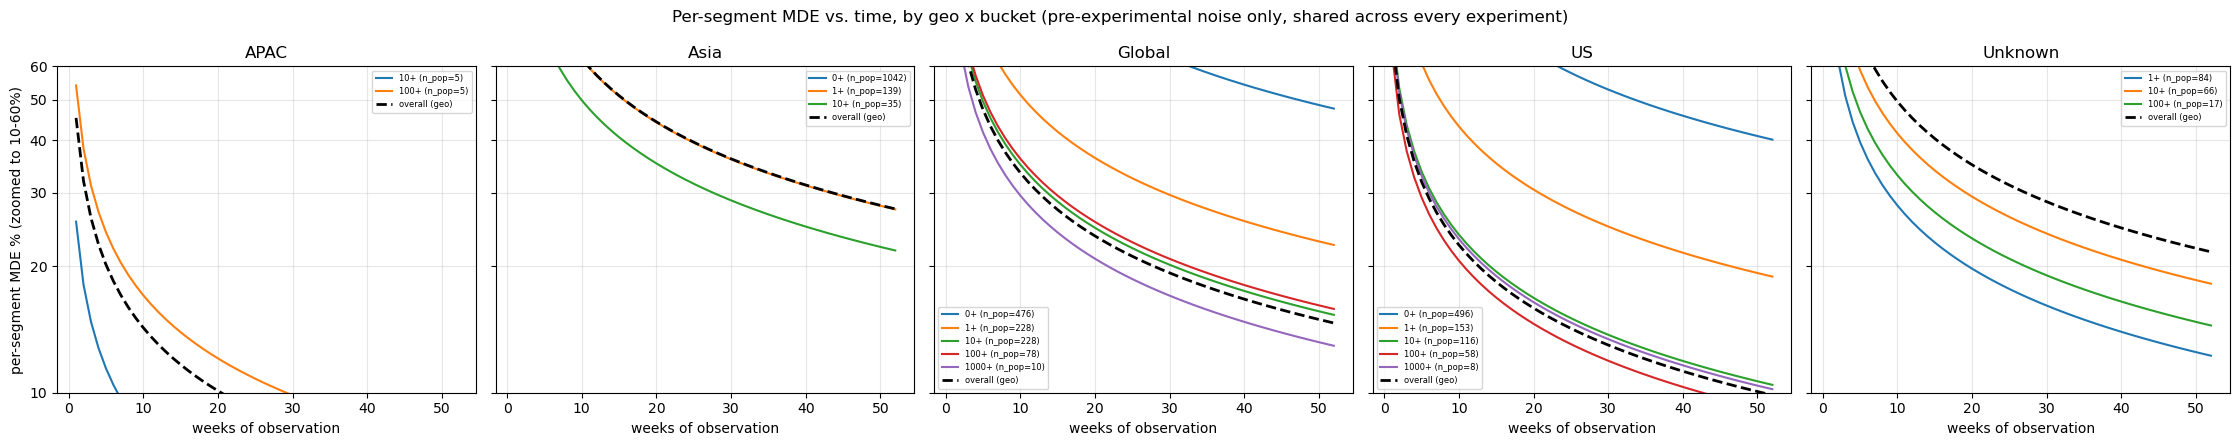

In [10]:
geos_present = sorted(cell_noise.index.get_level_values('geo').unique())
weeks_range = np.arange(1, 53)  # 1 to 52 weeks

# Zoomed to 10-60% MDE -- T2's price move (+-2.5%) is much smaller than the rollout's
# (-5%), so its true effect (if real) is plausibly smaller too; this is the band worth
# reading precisely, rather than the full log range down to <1%.
MDE_YLIM = (10, 60)

fig, axes = plt.subplots(1, len(geos_present), figsize=(4.5 * len(geos_present), 4.5), sharey=True)
if len(geos_present) == 1:
    axes = [axes]

for ax, geo in zip(axes, geos_present):
    for bucket in BUCKET_ORDER:
        key = (geo, bucket)
        if key not in cell_noise.index:
            continue
        row = cell_noise.loc[key]
        if row['baseline'] <= 0 or row['n_pop'] < 5:
            continue
        mde_curve = mde_pct_per_segment(row['sd_pre'], row['baseline'], weeks_range)
        ax.plot(weeks_range, mde_curve, label=f"{bucket} (n_pop={int(row['n_pop'])})")

    geo_rows = cell_noise.loc[geo]
    w = geo_rows['n_pop']
    sd_pre_geo = (geo_rows['sd_pre'] * w).sum() / w.sum()
    baseline_geo = (geo_rows['baseline'] * w).sum() / w.sum()
    mde_overall = mde_pct_per_segment(sd_pre_geo, baseline_geo, weeks_range)
    ax.plot(weeks_range, mde_overall, color='black', linewidth=2, linestyle='--', label='overall (geo)')

    ax.set_yscale('log')
    ax.set_ylim(*MDE_YLIM)
    ax.set_yticks([10, 20, 30, 40, 50, 60])
    ax.get_yaxis().set_major_formatter(plt.ScalarFormatter())
    ax.set_title(geo)
    ax.set_xlabel('weeks of observation')
    ax.legend(fontsize=6)
    ax.grid(alpha=0.3, which='both')

axes[0].set_ylabel('per-segment MDE % (zoomed to 10-60%)')
fig.suptitle('Per-segment MDE vs. time, by geo x bucket (pre-experimental noise only, shared across every experiment)')
plt.tight_layout()
plt.show()